The final lattice example showing a k-eigenvalue calculation in a fuel pin array. 

In [1]:
%run -i clean_script.py
import openmc 
import numpy as np

model = openmc.model.Model()
# Material definitions
materials=openmc.Materials()

# Assigning material numbers to make life easier when using VisIt
m1 = openmc.Material(material_id=1)
m1.add_nuclide('U235',0.02)
m1.add_nuclide('U238',0.98)
m1.set_density('g/cc',18)
materials.append(m1)

m2 = openmc.Material(material_id=3)
m2.add_nuclide('H1',1.0)
m2.add_nuclide('O16',2)
m2.set_density('g/cc',1)
materials.append(m2)

m3 = openmc.Material(material_id=2)
m3.add_element('Cd',1)
m3.set_density('g/cc',9)
materials.append(m3)

model.materials = materials

In [2]:
# Surface definitions
s1 = openmc.ZCylinder(r=60, boundary_type='vacuum')
s10 = openmc.ZCylinder(r=1.4)
s19 = openmc.ZPlane(60, boundary_type='vacuum')
s29 = openmc.ZPlane(-60, boundary_type='vacuum')
s301 = openmc.XPlane(10)
s302 = openmc.XPlane(-10)
s303 = openmc.YPlane(10)
s304 = openmc.YPlane(-10)

Had to do a few things to get this problem to run. 
1. introduce s999 which perfectly defines the domain of the rectlattice
2. define cextra in the function u2(), along with c3 (which remains unchanged)
3. 

<Axes: xlabel='x [cm]', ylabel='y [cm]'>

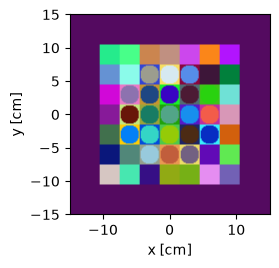

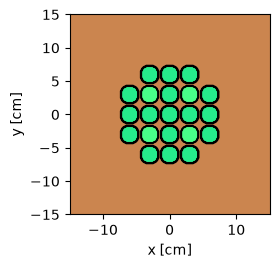

In [3]:
s999 = openmc.model.RectangularPrism(21,21)
c1 = openmc.Cell(fill=None, region=-s19&+s29&-s999)
def u1():
    c2 = openmc.Cell(fill=m2,region=-s301&+s302&-s303&+s304)
    return openmc.Universe(cells=[c2])

like_c3_list = []
def u2(mat=m1):
    c3_region = -s10
    c3 = openmc.Cell(fill=mat,region=c3_region)

    # Defines region outside fuel cylinders, but still inside pin pitch
    cextra = openmc.Cell(fill=m2,region=~c3_region)
    
    like_c3_list.append(c3)
    return openmc.Universe(cells=[c3,cextra])

c1_fill = openmc.RectLattice()
c1_fill.pitch = (3,3)
c1_fill.lower_left = (-10.5,-10.5)
c1_fill.universes = [
                     [u1(),u1(),u1(),u1(),u1(),u1(),u1()],
                     [u1(),u1(),u2(),u2(),u2(),u1(),u1()],
                     [u1(),u2(),u2(m3),u2(),u2(m3),u2(),u1()],
                     [u1(),u2(),u2(),u2(),u2(),u2(),u1()],
                     [u1(),u2(),u2(m3),u2(),u2(m3),u2(),u1()],
                     [u1(),u1(),u2(),u2(),u2(),u1(),u1()],
                     [u1(),u1(),u1(),u1(),u1(),u1(),u1()],
                    ]

c4_region = -s1&-s19&+s29 & +s999
c4 = openmc.Cell(fill=m2,region=c4_region)

c1.fill=c1_fill

geom = openmc.Geometry([c1,c4])
model.geometry=geom
geom.plot(width=(30,30))
geom.plot(color_by='material',width=(30,30),outline=True)

For interest, will get some particle tracks and overlay it onto a voxel plot in VisIt.

In [4]:
settings = openmc.Settings()
settings.run_mode = 'eigenvalue'
settings.particles=1000
settings.inactive=5
settings.batches=10 # specifies total batches

settings.track = [(10, 1, i) for i in range(1,50)]

# Specifies initial guess point
source = openmc.IndependentSource()
source.spatial = openmc.stats.Point((0,0,0))
source.energy = openmc.stats.delta_function(14e6)
settings.source = source

model.settings = settings

In [5]:
sp_filename = model.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

In [6]:
tracks = openmc.Tracks("tracks.h5")
tracks.write_to_vtk("tracks.vtp")

vx_plot = openmc.VoxelPlot()
vx_plot.pixels=(100,100,50)
vx_plot.filename='ex24_vox'
vx_plot.color_by='material'
vx_plot.width=(20,20,10)
vx_plot.to_vtk()

'ex24_vox.vti'